In [83]:
import pandas as pd

pd.set_option("display.max_columns", None)

datos = pd.read_csv("../data/raw/saber11_muestra.csv", low_memory=False)
datos["cole_naturaleza"].unique()

<ArrowStringArray>
['NO OFICIAL', 'OFICIAL', nan]
Length: 3, dtype: str

In [101]:
# 1. Conservar solo registros con puntaje global
trabajo = datos[datos["punt_global"].notna()]
print("Con puntaje global:", len(trabajo))

# 2. Eliminar registros duplicados
trabajo = trabajo.drop_duplicates()
print("Sin duplicados:", len(trabajo))

# 3. Conservar registros con estado PUBLICAR
trabajo = trabajo[trabajo["estu_estadoinvestigacion"] == "PUBLICAR"]
print("Estado PUBLICAR:", len(trabajo))

# 4. Eliminar puntajes iguales a cero
trabajo = trabajo[trabajo["punt_global"] > 0]
print("Puntaje mayor que 0:", len(trabajo))


# 5. Seleccionar las columnas a usar
columnas = [
    "cole_area_ubicacion", "cole_bilingue", "cole_caracter",
    "cole_depto_ubicacion", "cole_genero", "cole_jornada",
    "cole_naturaleza", "estu_fechanacimiento", "estu_depto_reside",
    "fami_educacionmadre", "fami_educacionpadre", "fami_estratovivienda",
    "fami_personashogar", "fami_cuartoshogar", "fami_tieneinternet",
    "fami_tienecomputador", "fami_tieneautomovil", "fami_tienelavadora",
    "punt_global", "periodo",
]

# 6. Eliminar filas con datos vacíos en esas columnas
completo = trabajo.dropna(subset=columnas)[columnas].copy()
print("Sin datos vacíos:", len(completo))


# 7. Unificar BOGOTA y BOGOTÁ
completo["cole_depto_ubicacion"] = completo["cole_depto_ubicacion"].replace({"BOGOTA": "BOGOTÁ"})

# 8. Unificar el formato de personas en el hogar
# Antes de 2017 vienen como palabras y después como rangos; todo pasa a rangos
completo["fami_personashogar"] = completo["fami_personashogar"].replace({
    "Una": "1 a 2", "Dos": "1 a 2", "Tres": "3 a 4", "Cuatro": "3 a 4",
    "Cinco": "5 a 6", "Seis": "5 a 6", "Siete": "7 a 8", "Ocho": "7 a 8",
    "Nueve": "9 o más", "Diez": "9 o más", "Once": "9 o más", "Doce o más": "9 o más",
})

# 9. Agrupar los valores altos de cuartos del hogar en "Seis o más"
completo["fami_cuartoshogar"] = completo["fami_cuartoshogar"].replace({
    "Seis": "Seis o más", "Seis o mas": "Seis o más", "Siete": "Seis o más",
    "Ocho": "Seis o más", "Nueve": "Seis o más", "Diez o más": "Seis o más",
})

# 10. Eliminar "NO APLICA" en carácter del colegio y el único estudiante extranjero
completo = completo[completo["cole_caracter"] != "NO APLICA"]
completo = completo[completo["estu_depto_reside"] != "EXTRANJERO"]
print("Tras las correcciones:", len(completo))


# 11. Calcular la edad aproximada: año del examen menos año de nacimiento
anio_examen = completo["periodo"] // 10
anio_nacimiento = pd.to_numeric(completo["estu_fechanacimiento"].str[-4:], errors="coerce")
completo["edad"] = anio_examen - anio_nacimiento

# 12. Eliminar edades imposibles (límites provisionales, se ajustan al ver la distribución)
edad_min, edad_max = 12, 60
completo = completo[completo["edad"].between(edad_min, edad_max)]
completo = completo.drop(columns="estu_fechanacimiento")
print("Con edad válida:", len(completo))


# 13. Revisión final
print("\nColumnas:", completo.columns.tolist())
print("Datos vacíos:", completo.isna().sum().sum())
print()
print(completo["fami_personashogar"].value_counts())
print()
print(completo["fami_cuartoshogar"].value_counts())
print()
print(completo["edad"].describe().round(1))

Con puntaje global: 203674
Sin duplicados: 187501
Estado PUBLICAR: 186953
Puntaje mayor que 0: 186950
Sin datos vacíos: 150320
Tras las correcciones: 149874
Con edad válida: 145647

Columnas: ['cole_area_ubicacion', 'cole_bilingue', 'cole_caracter', 'cole_depto_ubicacion', 'cole_genero', 'cole_jornada', 'cole_naturaleza', 'estu_depto_reside', 'fami_educacionmadre', 'fami_educacionpadre', 'fami_estratovivienda', 'fami_personashogar', 'fami_cuartoshogar', 'fami_tieneinternet', 'fami_tienecomputador', 'fami_tieneautomovil', 'fami_tienelavadora', 'punt_global', 'periodo', 'edad']
Datos vacíos: 0

fami_personashogar
3 a 4      82670
5 a 6      40559
1 a 2      12075
7 a 8       7661
9 o más     2682
Name: count, dtype: int64

fami_cuartoshogar
Tres          64405
Dos           43523
Cuatro        23604
Cinco          6448
Uno            4781
Seis o más     2886
Name: count, dtype: int64

count    145647.0
mean         18.1
std           3.3
min          12.0
25%          17.0
50%          1

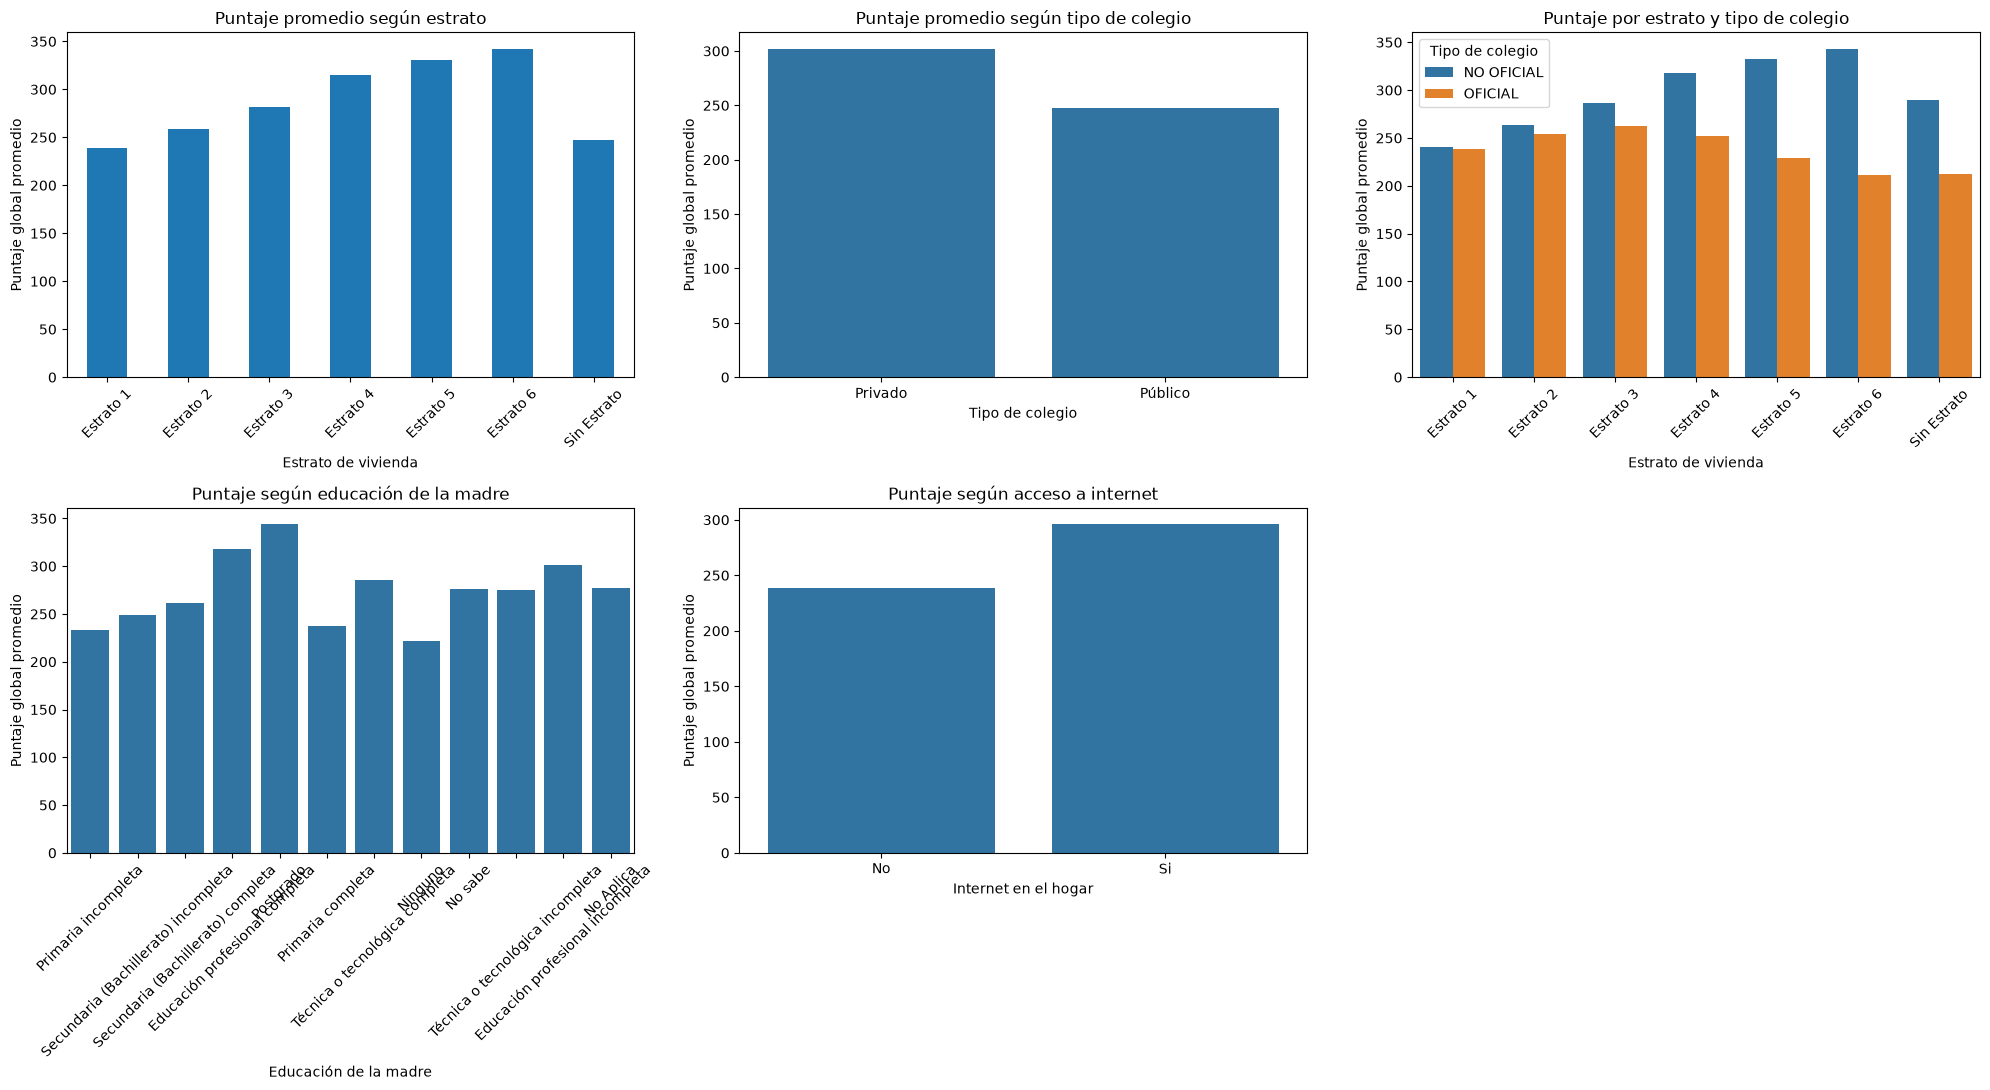

In [104]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes = axes.flatten()

# 1. Puntaje promedio según estrato de vivienda
promedio_estrato = (
    completo.groupby("fami_estratovivienda", observed=True)["punt_global"]
    .mean()
    .sort_index()
)

promedio_estrato.plot(kind="bar", ax=axes[0])
axes[0].set_title("Puntaje promedio según estrato")
axes[0].set_xlabel("Estrato de vivienda")
axes[0].set_ylabel("Puntaje global promedio")
axes[0].tick_params(axis="x", rotation=45)

# 2. Puntaje promedio según tipo de colegio
sns.barplot(
    data=completo,
    x="cole_naturaleza",
    y="punt_global",
    order=["NO OFICIAL", "OFICIAL"],
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Puntaje promedio según tipo de colegio")
axes[1].set_xlabel("Tipo de colegio")
axes[1].set_ylabel("Puntaje global promedio")
axes[1].set_xticks([0, 1], ["Privado", "Público"])

# 3. Puntaje por estrato y tipo de colegio
sns.barplot(
    data=completo,
    x="fami_estratovivienda",
    y="punt_global",
    hue="cole_naturaleza",
    hue_order=["NO OFICIAL", "OFICIAL"],
    errorbar=None,
    ax=axes[2]
)

axes[2].set_title("Puntaje por estrato y tipo de colegio")
axes[2].set_xlabel("Estrato de vivienda")
axes[2].set_ylabel("Puntaje global promedio")
axes[2].legend(title="Tipo de colegio")
axes[2].tick_params(axis="x", rotation=45)

# 4. Puntaje según educación de la madre
sns.barplot(
    data=completo,
    x="fami_educacionmadre",
    y="punt_global",
    errorbar=None,
    ax=axes[3]
)

axes[3].set_title("Puntaje según educación de la madre")
axes[3].set_xlabel("Educación de la madre")
axes[3].set_ylabel("Puntaje global promedio")
axes[3].tick_params(axis="x", rotation=45)

# 5. Puntaje según acceso a internet
sns.barplot(
    data=completo,
    x="fami_tieneinternet",
    y="punt_global",
    errorbar=None,
    ax=axes[4]
)

axes[4].set_title("Puntaje según acceso a internet")
axes[4].set_xlabel("Internet en el hogar")
axes[4].set_ylabel("Puntaje global promedio")

# Ocultar el sexto espacio, que no se utiliza
axes[5].set_visible(False)

plt.tight_layout()
plt.savefig("../reports/figures/exploracion_general.png", dpi=150, bbox_inches="tight")
plt.show()
